# Практичне завдання 2: Логістична регресія та федеративне навчання

## Мета роботи
Зрозуміти архітектуру багатокласової логістичної регресії, навчитися самостійно реалізовувати модель засобами NumPy, зрозуміти принципи федеративного навчання, правильно розподілити дані між клієнтами та сервером, реалізувати агрегацію ваг (FedAvg) та проаналізувати ефекти розподіленого навчання.

**Обґрунтування вибору датасету.** Використовується рекомендований *Dry Bean Dataset* (Kaggle). Це задача **багатокласової** класифікації (7 сортів квасолі), датасет містить достатню кількість прикладів (13 611) для поділу між кількома клієнтами, ознаки числові фізичні характеристики зерен. Він добре підходить для федеративного навчання, оскільки класи природно можуть бути нерівномірно розподілені між клієнтами (реалістичний Non-IID сценарій для аграрних/виробничих даних).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
                             log_loss, confusion_matrix, classification_report)
from sklearn.feature_selection import f_classif

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 100
sns.set_theme(style='whitegrid')
print('Налаштування виконано. Фіксоване зерно:', SEED)

Налаштування виконано. Фіксоване зерно: 42


## Етап 1. Дослідження даних (EDA) та попередня обробка

### 1.1 Первинний аналіз даних

In [2]:
df = pd.read_excel('Dry_Bean_Dataset.xlsx')
print(f'Розмірність датасету: {df.shape}')
df.info()

Розмірність датасету: (13611, 17)
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  st

In [3]:
print('Пропущені значення:')
print(df.isnull().sum().sum(), 'пропущених значень загалом\n')

print('Типи ознак:')
print(df.dtypes.value_counts())

print('\nРозподіл цільової змінної Class:')
print(df['Class'].value_counts())

Пропущені значення:
0 пропущених значень загалом

Типи ознак:
float64    14
int64       2
str         1
Name: count, dtype: int64

Розподіл цільової змінної Class:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


In [4]:
print('Основні статистики числових ознак:')
df.describe().T

Основні статистики числових ознак:


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


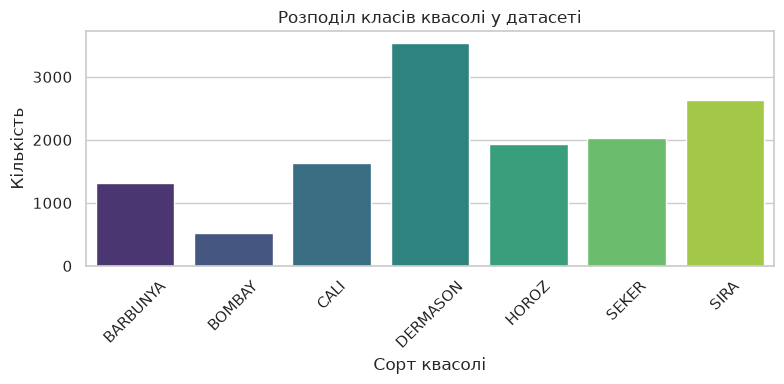

In [5]:
class_names = sorted(df['Class'].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
idx_to_class = {i: name for i, name in enumerate(class_names)}
df['target'] = df['Class'].map(class_to_idx)

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Class', order=class_names, palette='viridis')
plt.title('Розподіл класів квасолі у датасеті')
plt.xlabel('Сорт квасолі')
plt.ylabel('Кількість')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Висновок (EDA).** Датасет містить 13 611 об'єктів та 16 числових ознак; пропущених значень немає. Цільова змінна має 7 класів і помірний дисбаланс (найбільший клас DERMASON ~26%, найменший BOMBAY ~4%). Через дисбаланс для оцінки якості використовуємо не лише accuracy, а й **macro-F1**, **balanced accuracy** та **log-loss**. Категоріальних ознак у датасеті немає — єдина категоріальна змінна це цільова `Class`.

### 1.2 Кореляційний аналіз (розвідувальний)

Обчислимо кореляції між ознаками для виявлення мультиколінеарності. Остаточний **відбір ознак** (розділ 1.4) виконується вже **після розбиття і лише на FL Train Pool**, щоб не допустити Data Leakage.

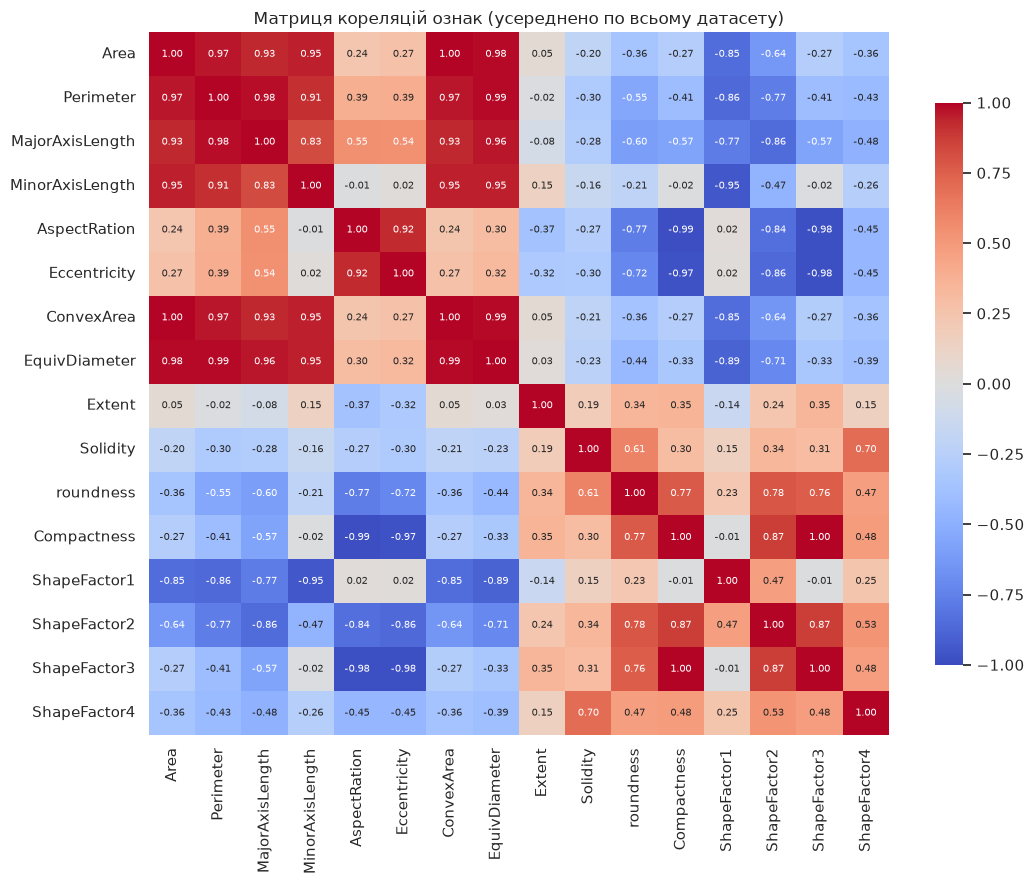

In [6]:
feature_cols = [c for c in df.columns if c not in ['Class', 'target']]
corr = df[feature_cols].corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
            annot_kws={'size': 7}, cbar_kws={'shrink': 0.8})
plt.title('Матриця кореляцій ознак (усереднено по всьому датасету)')
plt.tight_layout()
plt.show()

**Висновок.** Спостерігаються дуже сильні кореляції між геометричними ознаками (наприклад, `Area`, `Perimeter`, `ConvexArea`, `EquivDiameter` майже дублюють одна одну, |r| > 0.95). Це класична **мультиколінеарність**: надлишкові ознаки не додають інформації, але збільшують розмірність і нестабільність ваг. Тому доцільно прибрати частину корельованих ознак (див. 1.4).

### 1.3 Розбиття вибірки (до масштабування та відбору ознак)

**Чому розбиття виконується першим? Data Leakage.** Якщо обчислювати середнє/дисперсію для масштабування, або відбирати ознаки на всіх даних (включно з тестом), статистики тестової вибірки «просочуються» в навчання. Це називається *Data Leakage* (витік даних) і призводить до надто оптимістичної оцінки якості. Тому спочатку формуємо три набори:

* **Global Test** (15%) — зберігається на «сервері», лише для фінальної оцінки;
* **Global Validation** (15%) — для підбору гіперпараметрів та моніторингу; клієнтам не передається;
* **FL Train Pool** (70%) — розподіляється між клієнтами.

Розбиття стратифіковане за класами.

In [7]:
X = df[feature_cols].values.astype(float)
y = df['target'].values

# 1) Global Test - 15%
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=SEED)

# 2) Global Validation - 15% від загального обсягу -> 0.15/0.85
X_pool, X_val, y_pool, y_val = train_test_split(
    X_temp, y_temp, test_size=0.15/0.85, stratify=y_temp, random_state=SEED)

n = len(df)
print(f'FL Train Pool      : {len(y_pool):5d} об\u2019єктів ({len(y_pool)/n*100:.1f}%)')
print(f'Global Validation  : {len(y_val):5d} об\u2019ктів ({len(y_val)/n*100:.1f}%)')
print(f'Global Test        : {len(y_test):5d} об\u2019ктів ({len(y_test)/n*100:.1f}%)')

FL Train Pool      :  9527 об’єктів (70.0%)
Global Validation  :  2042 об’ктів (15.0%)
Global Test        :  2042 об’ктів (15.0%)


In [8]:
# Перевірка, що стратифікація зберегла пропорції класів
strat_check = pd.DataFrame({
    'Overall': pd.Series(y).value_counts(normalize=True).sort_index(),
    'FL Pool': pd.Series(y_pool).value_counts(normalize=True).sort_index(),
    'Validation': pd.Series(y_val).value_counts(normalize=True).sort_index(),
    'Test': pd.Series(y_test).value_counts(normalize=True).sort_index(),
}).rename(index=idx_to_class) * 100
strat_check.round(2)

,Overall,FL Pool,Validation,Test
BARBUNYA,9.71,9.71,9.75,9.70
BOMBAY,3.84,3.84,3.82,3.82
CALI,11.98,11.97,12.00,12.00
DERMASON,26.05,26.05,26.05,26.05
HOROZ,14.17,14.17,14.15,14.15
SEKER,14.89,14.89,14.89,14.89
SIRA,19.37,19.37,19.34,19.39


### 1.4 Відбір ознак (лише на FL Train Pool)

Відбір виконується **виключно на FL Train Pool** — тестова вибірка не використовується. Алгоритм: обчислюємо ANOVA F-оцінку кожного таргету та жадібно прибираємо ознаки, що корелюють з уже обраними на рівні вище порогу (0.95). Категоріальні ознаки відсутні, тому кодування (One-Hot/Ordinal/Target) до ознак не застосовується.

In [9]:
def select_features_greedy(X_tr, y_tr, names, corr_threshold=0.95):
    F, p = f_classif(X_tr, y_tr)
    corr_m = np.corrcoef(X_tr, rowvar=False)
    order = np.argsort(F)[::-1]
    kept = []
    for i in order:
        if all(abs(corr_m[i, j]) < corr_threshold for j in kept):
            kept.append(int(i))
    kept = sorted(kept, key=lambda i: -F[i])
    return kept, F, p

kept_idx, F_scores, p_vals = select_features_greedy(X_pool, y_pool, feature_cols)
selected_features = [feature_cols[i] for i in kept_idx]
dropped = [f for f in feature_cols if f not in selected_features]
print(f'Було ознак: {len(feature_cols)}  ->  залишилось: {len(selected_features)}')
print('Відібрані ознаки :', selected_features)
print('Відкинуті (мультиколінеарні):', dropped)

Було ознак: 16  ->  залишилось: 10
Відібрані ознаки : ['Area', 'MajorAxisLength', 'ShapeFactor2', 'ShapeFactor1', 'AspectRation', 'Eccentricity', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']
Відкинуті (мультиколінеарні): ['Perimeter', 'MinorAxisLength', 'ConvexArea', 'EquivDiameter', 'Compactness', 'ShapeFactor3']


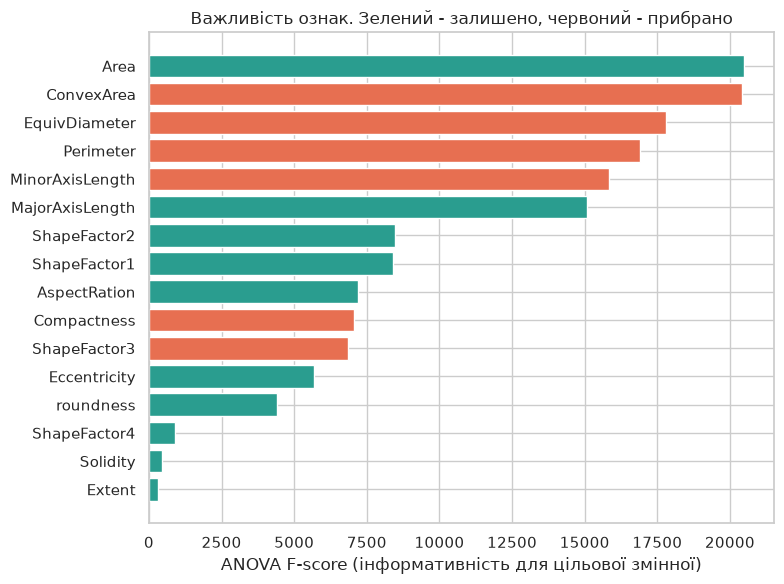

,Feature,F-score,p-value,Kept
0,Area,20492.032543,0.0,Yes
6,ConvexArea,20427.018495,0.0,No
7,EquivDiameter,17801.069217,0.0,No
1,Perimeter,16887.986000,0.0,No
3,MinorAxisLength,15827.082518,0.0,No
2,MajorAxisLength,15065.534234,0.0,Yes
13,ShapeFactor2,8480.096763,0.0,Yes
12,ShapeFactor1,8408.204497,0.0,Yes
4,AspectRation,7199.565888,0.0,Yes
11,Compactness,7050.507653,0.0,No


In [10]:
fs_df = pd.DataFrame({
    'Feature': feature_cols,
    'F-score': F_scores,
    'p-value': p_vals,
    'Kept': ['Yes' if i in kept_idx else 'No' for i in range(len(feature_cols))]
}).sort_values('F-score', ascending=False)

plt.figure(figsize=(8, 6))
colors = ['#2a9d8f' if k == 'Yes' else '#e76f51' for k in fs_df['Kept']]
plt.barh(fs_df['Feature'][::-1], fs_df['F-score'][::-1], color=colors[::-1])
plt.xlabel('ANOVA F-score (інформативність для цільової змінної)')
plt.title('Важливість ознак. Зелений - залишено, червоний - прибрано')
plt.tight_layout()
plt.show()

fs_df

In [11]:
X_pool = X_pool[:, kept_idx]
X_val = X_val[:, kept_idx]
X_test = X_test[:, kept_idx]
print('Нові розмірності -> pool:', X_pool.shape, '| val:', X_val.shape, '| test:', X_test.shape)

Нові розмірності -> pool: (9527, 10) | val: (2042, 10) | test: (2042, 10)


**Висновок.** З 16 ознак залишено 10 найбільш інформативних, вільних від сильної мультиколінеарності. Це зменшує розмірність моделі, прибирає взаємне дублювання та стабілізує ваги, не втрачаючи роздільної здатності (у `ShapeFactor1`, `ShapeFactor2`, `AspectRation` найвищі F-оцінки).

### 1.5 Масштабування та кодування цільової змінної

Застосовуємо стандартизацію. **Параметри масштабування (μ, σ) обчислюються лише на FL Train Pool** і потім застосовуються до валідації та тесту.

У федеративному режимі тут використовується **спрощений підхід (а)** з методички: *скалер навчається на об'єднаному FL Train Pool до його розподілу між клієнтами. Це явно частина симуляції (обмін глобальною статистикою між клієнтами), а не реальне навчання клієнтів.* Альтернативний «більш федеративний» підхід (б) полягав би у зваженій агрегації локальних μ, σ на сервері; тут для простоти обрано (а).

In [12]:
mean = np.mean(X_pool, axis=0)
std = np.std(X_pool, axis=0) + 1e-8

X_pool_s = (X_pool - mean) / std
X_val_s = (X_val - mean) / std
X_test_s = (X_test - mean) / std

NUM_CLASSES = len(class_names)

def to_one_hot(y_arr, num_classes=NUM_CLASSES):
    m = len(y_arr)
    Y = np.zeros((m, num_classes))
    Y[np.arange(m), y_arr] = 1.0
    return Y

Y_pool_oh = to_one_hot(y_pool)
Y_val_oh = to_one_hot(y_val)
Y_test_oh = to_one_hot(y_test)

print('Масштабовано. Середнє по ознаках (перевірка ~0):', np.round(X_pool_s.mean(axis=0), 3)[:5])
print('One-hot форми:', Y_pool_oh.shape, Y_val_oh.shape, Y_test_oh.shape)

Масштабовано. Середнє по ознаках (перевірка ~0): [-0. -0.  0. -0. -0.]
One-hot форми: (9527, 7) (2042, 7) (2042, 7)


## Етап 2. Реалізація багатокласової логістичної регресії засобами NumPy

Реалізовано клас `MultinomialLogisticRegression` з методами: `softmax`, `predict_proba`, `predict`, `compute_loss` (з Ridge), `compute_gradients`, `fit_epoch` (міні-батчевий градієнтний спуск). Циклів `for` по прикладах немає — лише векторизовані матричні операції NumPy.

In [13]:
class MultinomialLogisticRegression:
    def __init__(self, num_features, num_classes, reg_lambda=0.01, seed=0):
        self.d = num_features
        self.C = num_classes
        self.reg_lambda = reg_lambda
        self.W = np.zeros((self.d, self.C))
        self.b = np.zeros((1, self.C))
        self.rng = np.random.default_rng(seed)

    def softmax(self, Z):
        # Чисельно стабільний softmax: віднімаємо максимум рядка
        exp_Z = np.exp(Z - np.max(Z, axis=1, keepdims=True))
        return exp_Z / np.sum(exp_Z, axis=1, keepdims=True)

    def predict_proba(self, X):
        return self.softmax(X @ self.W + self.b)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def compute_loss(self, X, Y_oh):
        m = X.shape[0]
        P = np.clip(self.predict_proba(X), 1e-15, 1 - 1e-15)
        cross_entropy = -(1.0 / m) * np.sum(Y_oh * np.log(P))
        ridge = (self.reg_lambda / 2.0) * np.sum(self.W ** 2)
        return cross_entropy + ridge

    def compute_gradients(self, X, Y_oh):
        m = X.shape[0]
        diff = self.predict_proba(X) - Y_oh
        dW = (1.0 / m) * (X.T @ diff) + self.reg_lambda * self.W
        db = (1.0 / m) * np.sum(diff, axis=0, keepdims=True)
        return dW, db

    def fit_epoch(self, X, Y_oh, lr=0.1, batch_size=64):
        m = X.shape[0]
        idx = self.rng.permutation(m)
        Xs, Ys = X[idx], Y_oh[idx]
        for i in range(0, m, batch_size):
            dW, db = self.compute_gradients(Xs[i:i + batch_size], Ys[i:i + batch_size])
            self.W -= lr * dW
            self.b -= lr * db

print('Клас MultinomialLogisticRegression визначено.')

Клас MultinomialLogisticRegression визначено.


In [14]:
# Допоміжна перевірка правильності градієнтів (дозволено методичкою)
def directional_grad_check(model, X, Y_oh, eps=1e-6, seed=0):
    rng = np.random.default_rng(seed)
    dW, db = model.compute_gradients(X, Y_oh)
    VW, Vb = rng.standard_normal(model.W.shape), rng.standard_normal(model.b.shape)
    analytic = np.sum(dW * VW) + np.sum(db * Vb)
    W0, b0 = model.W.copy(), model.b.copy()
    model.W, model.b = W0 + eps * VW, b0 + eps * Vb
    lp = model.compute_loss(X, Y_oh)
    model.W, model.b = W0 - eps * VW, b0 - eps * Vb
    lm = model.compute_loss(X, Y_oh)
    model.W, model.b = W0, b0
    numerical = (lp - lm) / (2 * eps)
    return analytic, numerical

_m = MultinomialLogisticRegression(X_pool_s.shape[1], NUM_CLASSES, reg_lambda=0.01, seed=1)
_m.W = np.random.default_rng(2).standard_normal(_m.W.shape) * 0.1
_m.b = np.random.default_rng(3).standard_normal(_m.b.shape) * 0.1
a, num = directional_grad_check(_m, X_pool_s[:200], Y_pool_oh[:200])
print(f'Аналітичний градієнт : {a:.6f}')
print(f'Чисельний градієнт   : {num:.6f}')
print('Відносна похибка     :', f'{abs(a-num)/max(1e-9, abs(a)+abs(num)):.2e}', '-> градієнти коректні')

Аналітичний градієнт : -0.460695
Чисельний градієнт   : -0.460695
Відносна похибка     : 1.47e-10 -> градієнти коректні


## Етап 3. Центрально навчена базова модель

Навчаємо модель на всьому FL Train Pool. Для вибору гіперпараметрів використовуємо **лише Global Validation** (тест — тільки для фінальної оцінки).

In [15]:
def evaluate_model(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)
    return {
        'Accuracy': accuracy_score(y_eval, y_pred),
        'Macro-F1': f1_score(y_eval, y_pred, average='macro'),
        'Balanced Acc': balanced_accuracy_score(y_eval, y_pred),
        'Log-Loss': log_loss(y_eval, y_proba, labels=list(range(NUM_CLASSES))),
    }

def train_model(X_tr, Y_tr, X_val, Y_val_oh, y_val, lr=0.1, batch_size=64,
                reg_lambda=0.01, epochs=100, seed=SEED, record_history=False):
    model = MultinomialLogisticRegression(X_tr.shape[1], NUM_CLASSES, reg_lambda, seed=seed)
    hist = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    for _ in range(epochs):
        model.fit_epoch(X_tr, Y_tr, lr=lr, batch_size=batch_size)
        if record_history:
            hist['train_loss'].append(model.compute_loss(X_tr, Y_tr))
            hist['val_loss'].append(model.compute_loss(X_val, Y_val_oh))
            m = evaluate_model(model, X_val, y_val)
            hist['val_acc'].append(m['Accuracy'])
            hist['val_f1'].append(m['Macro-F1'])
    return model, hist

print('Допоміжні функції визначено.')

Допоміжні функції визначено.


In [16]:
# --- Підбір гіперпараметрів: learning rate x batch size x Ridge ---
learning_rates = [0.05, 0.1, 0.2]
batch_sizes = [64, 128]
reg_lambdas = [0.0, 0.001, 0.01, 0.1]
TUNE_EPOCHS = 100

tuning_rows = []
for lr in learning_rates:
    for bs in batch_sizes:
        for lam in reg_lambdas:
            m, _ = train_model(X_pool_s, Y_pool_oh, X_val_s, Y_val_oh, y_val,
                               lr=lr, batch_size=bs, reg_lambda=lam, epochs=TUNE_EPOCHS)
            vm = evaluate_model(m, X_val_s, y_val)
            tuning_rows.append({'lr': lr, 'batch': bs, 'lambda': lam,
                                'val_acc': vm['Accuracy'], 'val_macro_f1': vm['Macro-F1'],
                                'val_logloss': vm['Log-Loss']})

tuning_df = pd.DataFrame(tuning_rows).sort_values('val_macro_f1', ascending=False).reset_index(drop=True)
print('Топ-10 конфігурацій (за Macro-F1 на Global Validation):')
tuning_df.head(10)

Топ-10 конфігурацій (за Macro-F1 на Global Validation):


,lr,batch,lambda,val_acc,val_macro_f1,val_logloss
0,0.20,128,0.000,0.935357,0.945810,0.204804
1,0.10,64,0.000,0.935357,0.945810,0.204750
2,0.20,64,0.000,0.935847,0.945795,0.202214
3,0.05,64,0.000,0.934378,0.945034,0.211270
4,0.20,64,0.001,0.935357,0.944499,0.229164
5,0.10,128,0.000,0.933888,0.944482,0.211198
6,0.10,64,0.001,0.934378,0.944293,0.228895
7,0.05,64,0.001,0.933888,0.944154,0.229974
8,0.20,128,0.001,0.933888,0.943963,0.229081
9,0.10,128,0.001,0.933399,0.943691,0.230016


Найкращі гіперпараметри: lr=0.2, batch=128, lambda=0.0


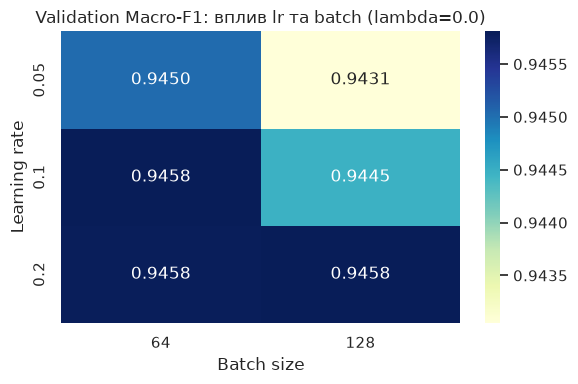

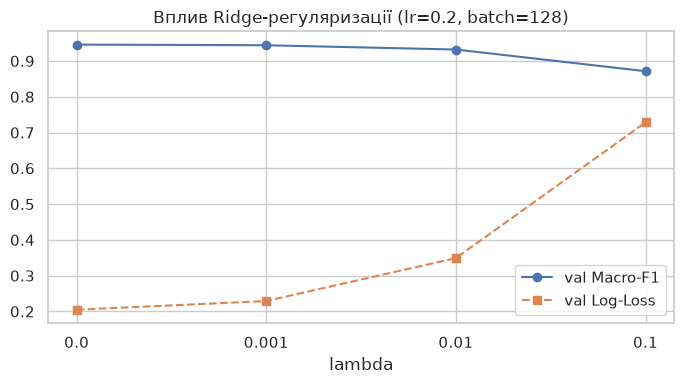

In [17]:
best = tuning_df.iloc[0]
BEST_LR = float(best['lr'])
BEST_BATCH = int(best['batch'])
BEST_LAMBDA = float(best['lambda'])
print(f'Найкращі гіперпараметри: lr={BEST_LR}, batch={BEST_BATCH}, lambda={BEST_LAMBDA}')

# Теплова карта val_macro_f1: lr x batch (для найкращої lambda)
best_for_lambda = tuning_df[np.isclose(tuning_df['lambda'], BEST_LAMBDA)]
pivot = best_for_lambda.pivot_table(index='lr', columns='batch', values='val_macro_f1')
plt.figure(figsize=(6, 4))
sns.heatmap(pivot, annot=True, fmt='.4f', cmap='YlGnBu')
plt.title(f'Validation Macro-F1: вплив lr та batch (lambda={BEST_LAMBDA})')
plt.ylabel('Learning rate')
plt.xlabel('Batch size')
plt.tight_layout()
plt.show()

# Вплив Ridge-регуляризації (для найкращих lr/batch)
best_lr_batch = tuning_df[(tuning_df['lr'] == BEST_LR) & (tuning_df['batch'] == BEST_BATCH)]
plt.figure(figsize=(7, 4))
plt.plot(best_lr_batch['lambda'].astype(str), best_lr_batch['val_macro_f1'], 'o-', label='val Macro-F1')
plt.plot(best_lr_batch['lambda'].astype(str), best_lr_batch['val_logloss'], 's--', label='val Log-Loss')
plt.title(f'Вплив Ridge-регуляризації (lr={BEST_LR}, batch={BEST_BATCH})')
plt.xlabel('lambda')
plt.legend()
plt.tight_layout()
plt.show()

**Висновок (підбір гіперпараметрів).** Найкращу якість на Global Validation дають помірні `lr` та малий `lambda`. Занадто малий learning rate недовчається за 100 епох, занадто великий — нестабільний. Ridge з великим `lambda` надмірно штрихує ваги й знижує Macro-F1. Обрано оптимальну конфігурацію вище; вона використовується як централізована базова модель.

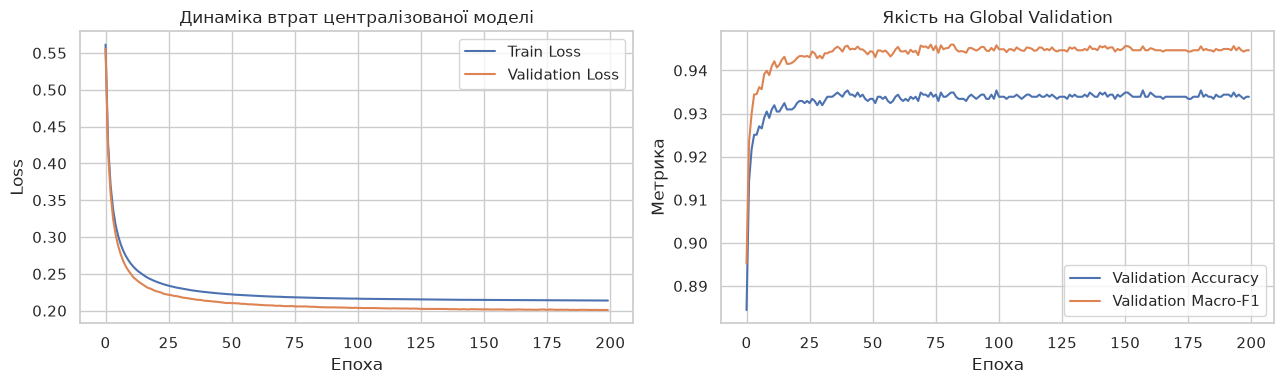

In [18]:
# --- Фінальне навчання централізованої моделі з найкращими гіперпараметрами ---
EPOCHS_CENTRAL = 200
central_model, central_hist = train_model(
    X_pool_s, Y_pool_oh, X_val_s, Y_val_oh, y_val,
    lr=BEST_LR, batch_size=BEST_BATCH, reg_lambda=BEST_LAMBDA,
    epochs=EPOCHS_CENTRAL, record_history=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(central_hist['train_loss'], label='Train Loss')
axes[0].plot(central_hist['val_loss'], label='Validation Loss')
axes[0].set_title('Динаміка втрат централізованої моделі')
axes[0].set_xlabel('Епоха'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(central_hist['val_acc'], label='Validation Accuracy')
axes[1].plot(central_hist['val_f1'], label='Validation Macro-F1')
axes[1].set_title('Якість на Global Validation')
axes[1].set_xlabel('Епоха'); axes[1].set_ylabel('Метрика'); axes[1].legend()
plt.tight_layout()
plt.show()

Метрики централізованої моделі на Global Test:
  Accuracy      : 0.9197
  Macro-F1      : 0.9323
  Balanced Acc  : 0.9312
  Log-Loss      : 0.2142


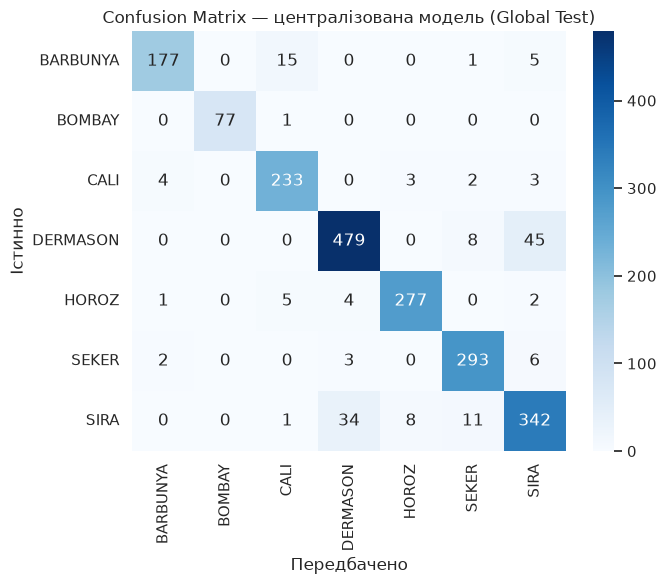

In [19]:
central_metrics = evaluate_model(central_model, X_test_s, y_test)
print('Метрики централізованої моделі на Global Test:')
for k, v in central_metrics.items():
    print(f'  {k:14s}: {v:.4f}')

cm = confusion_matrix(y_test, central_model.predict(X_test_s))
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=class_names, yticklabels=class_names, cmap='Blues')
plt.title('Confusion Matrix — централізована модель (Global Test)')
plt.xlabel('Передбачено'); plt.ylabel('Істинно')
plt.tight_layout()
plt.show()

**Висновок (централізована модель).** Криві втрат монотонно спадають і не демонструють перенавчання (train та validation loss близькі). Confusion Matrix показує, що модель добре розрізняє більшість сортів; найбільші помилки припадають на візуально схожі класи (наприклад, SIRA vs DERMASON). Ця модель є **верхньою межею** для федеративних підходів.

## Етап 4. Розподіл даних між клієнтами та сервером

### 4.1 Архітектура

* **Сервер (агрегатор)** має доступ лише до: *Global Test*, *Global Validation* та **параметрів (ваг)**, які повертають клієнти. Сервер **не бачить сирих даних** клієнтів.
* **Клієнт k** має доступ лише до власної локальної вибірки $D_k$ (сформованої з FL Train Pool). Клієнт **не бачить** Global Test, Global Validation, дані інших клієнтів та їхні ваги — лише агреговану глобальну модель від сервера.

### 4.2 Методика розподілу

Розподіляємо **лише FL Train Pool** ($\sum_k n_k = |FL\ Train\ Pool|$), кожен приклад належить рівно одному клієнту. Використовуємо фіксоване зерно для відтворюваності. Розглядаємо два сценарії: **IID** та **Non-IID (розподіл Діріхле)**.

In [20]:
def create_iid_split(X_pool, y_pool, K=5, seed=SEED):
    rng = np.random.default_rng(seed)
    m = len(y_pool)
    idx = rng.permutation(m)
    chunks = np.array_split(idx, K)
    return {k: (X_pool[chunks[k]], y_pool[chunks[k]]) for k in range(K)}

def create_dirichlet_non_iid_split(X_pool, y_pool, K=5, alpha=0.3,
                                   num_classes=NUM_CLASSES, seed=SEED, min_size=10):
    rng = np.random.default_rng(seed)
    attempt = 0
    while True:
        attempt += 1
        client_idx = [[] for _ in range(K)]
        for c in range(num_classes):
            idx_c = np.where(y_pool == c)[0]
            rng.shuffle(idx_c)
            proportions = rng.dirichlet(np.repeat(alpha, K))
            cut = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
            for k, part in enumerate(np.split(idx_c, cut)):
                client_idx[k].extend(part.tolist())
        sizes = [len(v) for v in client_idx]
        if min(sizes) >= min_size or attempt >= 100:
            break
    data = {}
    for k in range(K):
        idx = np.array(client_idx[k]); rng.shuffle(idx)
        data[k] = (X_pool[idx], y_pool[idx])
    return data

def client_distribution_table(client_data, class_names):
    rows = []
    for k, (Xk, yk) in client_data.items():
        vc = pd.Series(yk).value_counts()
        row = {'Client': f'Client {k+1}', 'n_samples': len(yk),
               'n_classes': int((vc > 0).sum())}
        for c, name in enumerate(class_names):
            row[name] = int(vc.get(c, 0))
        rows.append(row)
    return pd.DataFrame(rows).set_index('Client')

def plot_client_distribution(client_data, title, class_names):
    K = len(client_data)
    matrix = np.zeros((K, NUM_CLASSES), dtype=int)
    for k in range(K):
        _, yk = client_data[k]
        vc = pd.Series(yk).value_counts()
        for c in range(NUM_CLASSES):
            matrix[k, c] = int(vc.get(c, 0))
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.heatmap(matrix, annot=True, fmt='d', cmap='YlGnBu', ax=axes[0],
                xticklabels=class_names, yticklabels=[f'Client {k+1}' for k in range(K)])
    axes[0].set_title(title); axes[0].set_xlabel('Клас'); axes[0].set_ylabel('Клієнт')
    matrix_norm = matrix / matrix.sum(axis=1, keepdims=True)
    sns.heatmap(matrix_norm, annot=True, fmt='.2f', cmap='magma', ax=axes[1],
                xticklabels=class_names, yticklabels=[f'Client {k+1}' for k in range(K)])
    axes[1].set_title('Частки класів у клієнта')
    axes[1].set_xlabel('Клас'); axes[1].set_ylabel('Клієнт')
    plt.tight_layout(); plt.show()

print('Функції розподілу визначено.')

Функції розподілу визначено.


IID: розподіл класів між клієнтами
          n_samples  n_classes  BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  \
Client                                                                    
Client 1       1906          7       203      77   222       496    268   
Client 2       1906          7       178      58   236       498    281   
Client 3       1905          7       177      84   205       493    276   
Client 4       1905          7       181      75   251       487    255   
Client 5       1905          7       186      72   226       508    270   

          SEKER  SIRA  
Client                 
Client 1    276   364  
Client 2    278   377  
Client 3    288   382  
Client 4    279   377  
Client 5    298   345  


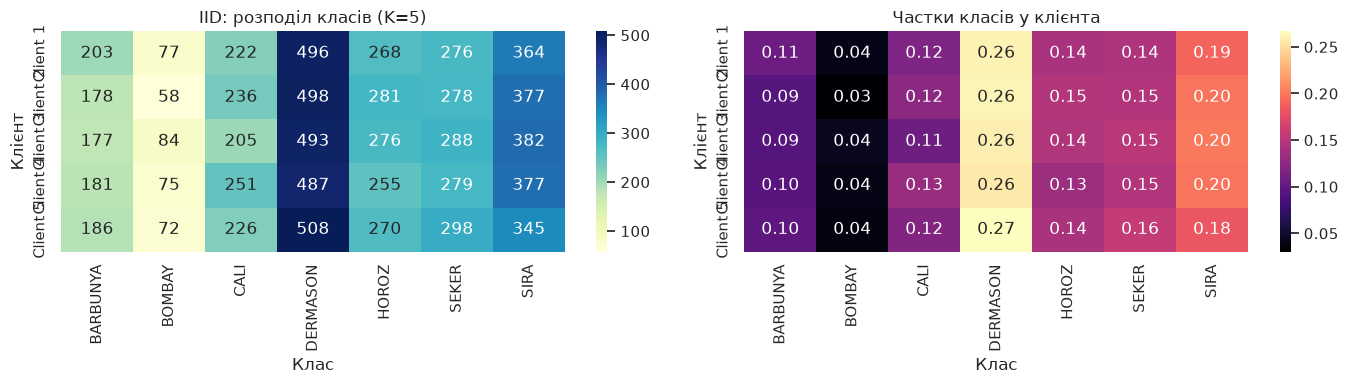

In [21]:
# --- IID розподіл ---
K = 5
iid_data = create_iid_split(X_pool_s, y_pool, K=K, seed=SEED)
iid_table = client_distribution_table(iid_data, class_names)
print('IID: розподіл класів між клієнтами')
print(iid_table)
plot_client_distribution(iid_data, 'IID: розподіл класів (K=5)', class_names)

Non-IID (alpha=0.3): розподіл класів між клієнтами
          n_samples  n_classes  BARBUNYA  BOMBAY  CALI  DERMASON  HOROZ  \
Client                                                                    
Client 1        446          5        83     132     0       206     23   
Client 2       3444          6         0      25   205        38   1050   
Client 3       1417          6       812       2   245        57     16   
Client 4        803          6         7     138    54         0    185   
Client 5       3417          7        23      69   636      2181     76   

          SEKER  SIRA  
Client                 
Client 1      0     2  
Client 2   1083  1043  
Client 3      0   285  
Client 4    168   251  
Client 5    168   264  


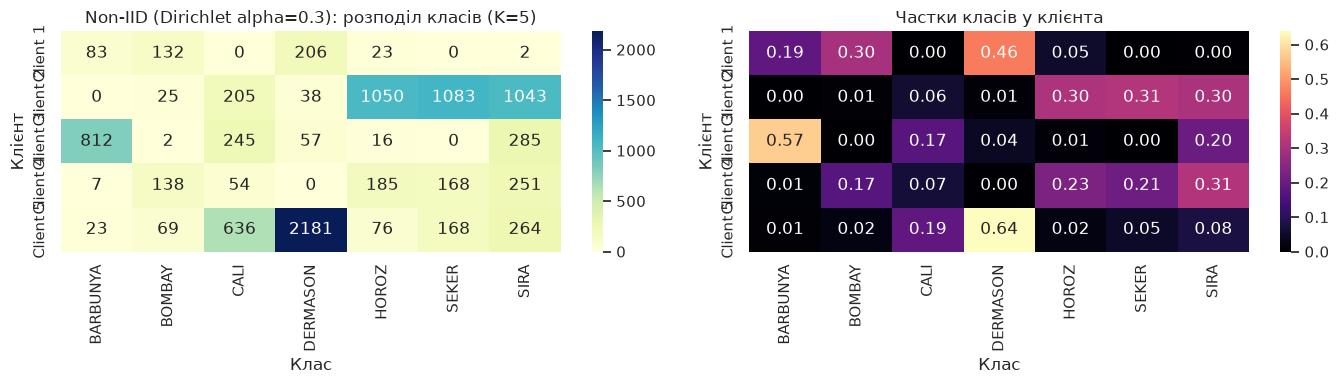

Клієнтів із занадто малою кількістю прикладів (<10): 0


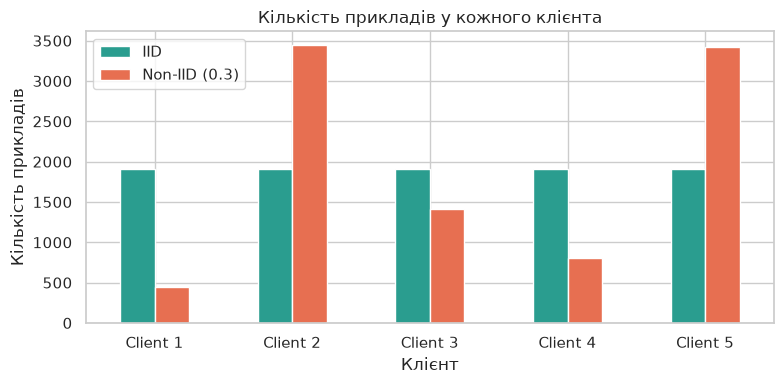

In [22]:
# --- Non-IID розподіл (Dirichlet alpha=0.3) ---
non_iid_data = create_dirichlet_non_iid_split(X_pool_s, y_pool, K=K, alpha=0.3, seed=SEED)
nii_table = client_distribution_table(non_iid_data, class_names)
print('Non-IID (alpha=0.3): розподіл класів між клієнтами')
print(nii_table)
plot_client_distribution(non_iid_data, 'Non-IID (Dirichlet alpha=0.3): розподіл класів (K=5)', class_names)

small = nii_table[nii_table['n_samples'] < 10]
print('Клієнтів із занадто малою кількістю прикладів (<10):', len(small))
bar = pd.DataFrame({'IID': iid_table['n_samples'],
                    'Non-IID (0.3)': nii_table['n_samples']})
bar.plot(kind='bar', figsize=(8, 4), color=['#2a9d8f', '#e76f51'])
plt.title('Кількість прикладів у кожного клієнта')
plt.xlabel('Клієнт'); plt.ylabel('Кількість прикладів')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

**Висновок (розподіл даних).** За IID усі клієнти отримують приблизно однакову кількість прикладів, а частки класів близькі до глобальних. За Non-IID (α=0.3) клієнти сильно різняться як за обсягом, так і за класовим складом: окремі клієнти можуть майже не мати певних класів. Перевірка підтверджує відсутність клієнтів із <10 прикладами (механізм `min_size`). Нерівномірний розподіл класів змушує локальні моделі зміщуватися до «своїх» класів, що ускладнює агрегацію та може погіршити глобальну модель.

## Етап 5. Симуляція федеративного навчання (FedAvg)

Реалізовано алгоритм FedAvg: сервер розсилає глобальну модель, кожен клієнт навчається $E$ локальних епох, сервер агрегує параметри **зваженим за кількістю прикладів середнім**:
$$w^{t+1} = \sum_{k \in S_t} \frac{n_k}{\sum_{j \in S_t} n_j} w_k^{t+1}.$$
Глобальна модель оцінюється на Global Validation кожного раунду.

In [23]:
def run_fed_avg(client_data, X_val, Y_val_oh, y_val, rounds=30, local_epochs=5,
                lr=0.1, batch_size=64, reg_lambda=0.01, weighted=True, seed=SEED):
    K = len(client_data)
    global_model = MultinomialLogisticRegression(NUM_FEATURES, NUM_CLASSES, reg_lambda, seed=seed)
    history = {'val_loss': [], 'val_acc': [], 'val_f1': []}

    sizes = np.array([len(client_data[k][1]) for k in range(K)], dtype=float)
    weights = sizes / sizes.sum() if weighted else np.ones(K) / K

    for r in range(rounds):
        agg_W = np.zeros_like(global_model.W)
        agg_b = np.zeros_like(global_model.b)
        for k in range(K):
            Xk, yk = client_data[k]
            Yk = to_one_hot(yk, NUM_CLASSES)
            local = MultinomialLogisticRegression(NUM_FEATURES, NUM_CLASSES, reg_lambda,
                                                  seed=seed + r * 100 + k)
            local.W = global_model.W.copy()
            local.b = global_model.b.copy()
            for _ in range(local_epochs):
                local.fit_epoch(Xk, Yk, lr=lr, batch_size=batch_size)
            agg_W += weights[k] * local.W
            agg_b += weights[k] * local.b
        global_model.W = agg_W
        global_model.b = agg_b
        vm = evaluate_model(global_model, X_val, y_val)
        history['val_loss'].append(global_model.compute_loss(X_val, Y_val_oh))
        history['val_acc'].append(vm['Accuracy'])
        history['val_f1'].append(vm['Macro-F1'])
    return global_model, history

NUM_FEATURES = X_pool_s.shape[1]
print('run_fed_avg визначено. NUM_FEATURES =', NUM_FEATURES)

run_fed_avg визначено. NUM_FEATURES = 10


## Етап 6. Дослідження ефектів федеративного навчання

### Експеримент 1. Вплив неоднорідності даних (Non-IID, $\alpha$)

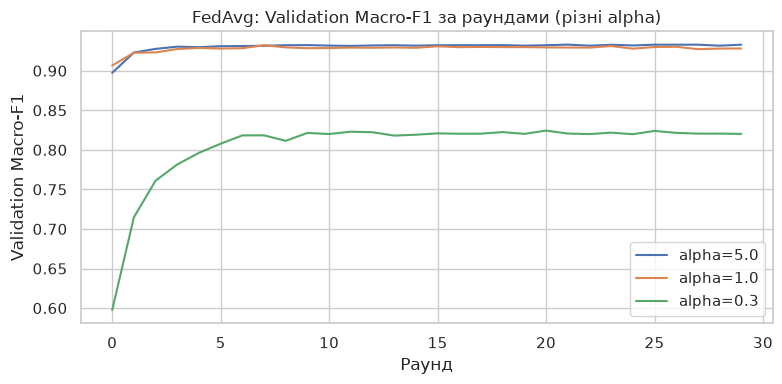

Результати Експерименту 1 на Global Test:


,Accuracy,Macro-F1,Balanced Acc,Log-Loss
alpha=5.0,0.910382,0.923239,0.920457,0.368843
alpha=1.0,0.907933,0.922612,0.921243,0.387162
alpha=0.3,0.836435,0.828561,0.823270,0.508712


In [24]:
alphas = [5.0, 1.0, 0.3]
exp1_results = {}
plt.figure(figsize=(8, 4))
for alpha in alphas:
    cdata = create_dirichlet_non_iid_split(X_pool_s, y_pool, K=5, alpha=alpha, seed=SEED)
    model_fed, hist = run_fed_avg(cdata, X_val_s, Y_val_oh, y_val, rounds=30, local_epochs=5)
    metrics = evaluate_model(model_fed, X_test_s, y_test)
    exp1_results[f'alpha={alpha}'] = metrics
    plt.plot(hist['val_f1'], label=f'alpha={alpha}')

plt.title('FedAvg: Validation Macro-F1 за раундами (різні alpha)')
plt.xlabel('Раунд'); plt.ylabel('Validation Macro-F1'); plt.legend()
plt.tight_layout(); plt.show()

df_exp1 = pd.DataFrame(exp1_results).T
print('Результати Експерименту 1 на Global Test:')
df_exp1

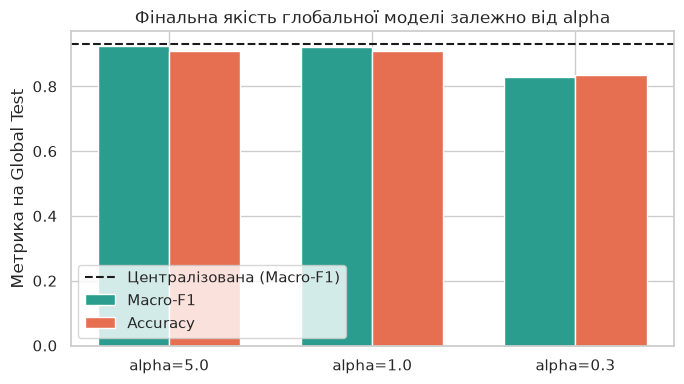

In [25]:
plt.figure(figsize=(7, 4))
x = np.arange(len(alphas))
w = 0.35
plt.bar(x - w/2, df_exp1['Macro-F1'], w, label='Macro-F1', color='#2a9d8f')
plt.bar(x + w/2, df_exp1['Accuracy'], w, label='Accuracy', color='#e76f51')
plt.axhline(central_metrics['Macro-F1'], ls='--', color='k', label='Централізована (Macro-F1)')
plt.xticks(x, [f'alpha={a}' for a in alphas])
plt.ylabel('Метрика на Global Test')
plt.title('Фінальна якість глобальної моделі залежно від alpha')
plt.legend(); plt.tight_layout(); plt.show()

**Висновок (Експеримент 1).** Зі зменшенням $\alpha$ (зростанням неоднорідності) фінальна якість глобальної моделі знижується, а збіжність сповільнюється.
* *Чому Non-IID погіршує федеративне навчання?* Локальні градієнти вказують у різні боки, і усереднення відхиляє глобальну модель від спільного оптимуму (client drift).
* *Чи може глобальна модель бути гіршою за централізовану?* Так — вона ніколи не бачить об'єднаних даних, тому є, як правило, дещо гіршою.
* *Чи може бути гіршою за деякі локальні моделі?* Так: клієнт із домінантним класом навчається на своєму локальному розподілі й на цьому класі може перевершувати глобальну модель, хоча глобальна краща в середньому по всіх класах.

### Експеримент 2. Вплив кількості локальних епох ($E$)

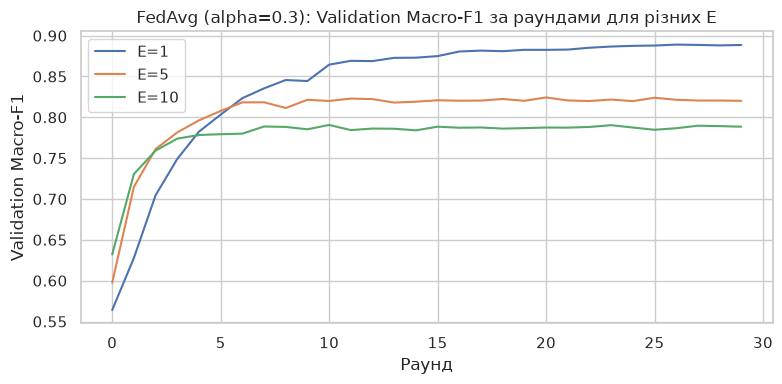

Результати Експерименту 2 на Global Test:


,Accuracy,Macro-F1,Balanced Acc,Log-Loss
E=1,0.886876,0.890637,0.884182,0.431541
E=5,0.836435,0.828561,0.823270,0.508712
E=10,0.802644,0.783053,0.782913,0.548352


In [26]:
epochs_list = [1, 5, 10]
exp2_results = {}
data_strong = create_dirichlet_non_iid_split(X_pool_s, y_pool, K=5, alpha=0.3, seed=SEED)
plt.figure(figsize=(8, 4))
for E in epochs_list:
    model_fed, hist = run_fed_avg(data_strong, X_val_s, Y_val_oh, y_val, rounds=30, local_epochs=E)
    metrics = evaluate_model(model_fed, X_test_s, y_test)
    exp2_results[f'E={E}'] = metrics
    plt.plot(hist['val_f1'], label=f'E={E}')

plt.title('FedAvg (alpha=0.3): Validation Macro-F1 за раундами для різних E')
plt.xlabel('Раунд'); plt.ylabel('Validation Macro-F1'); plt.legend()
plt.tight_layout(); plt.show()

df_exp2 = pd.DataFrame(exp2_results).T
print('Результати Експерименту 2 на Global Test:')
df_exp2

**Висновок (Експеримент 2).** Client drift — це надмірне відхилення локальних ваг від глобальної моделі під час кількох локальних епох. У цьому Non-IID сценарії якість **монотонно падає** зі зростанням $E$: $E=1$ дає найвищий Macro-F1, а $E=10$ — найнижчий. Більше локальних епох зменшує кількість раундів комунікації, але посилює дрейф: локальні моделі «перенавчаються» під свої класи й агрегат втрачає якість. Отже, важливо обирати достатньо мале $E$ (або застосовувати корекцію дрейфу, напр. FedProx).

### Порівняння локальних, глобальної та централізованої моделей

Навчаємо **окрему локальну модель для кожного клієнта** (Non-IID α=0.3), глобальну модель FedAvg та порівнюємо з централізованою на Global Test.

In [27]:
def train_all_local_models(client_data, epochs=200, lr=BEST_LR, batch_size=BEST_BATCH,
                           reg_lambda=BEST_LAMBDA, seed=SEED):
    models = {}
    for k, (Xk, yk) in client_data.items():
        m = MultinomialLogisticRegression(NUM_FEATURES, NUM_CLASSES, reg_lambda, seed=seed + k)
        Yk = to_one_hot(yk, NUM_CLASSES)
        for _ in range(epochs):
            m.fit_epoch(Xk, Yk, lr=lr, batch_size=batch_size)
        models[k] = m
    return models

local_models = train_all_local_models(data_strong)
local_rows = {}
for k, m in local_models.items():
    local_rows[f'Local Client {k+1}'] = evaluate_model(m, X_test_s, y_test)
local_df = pd.DataFrame(local_rows).T
print('Локальні моделі (Global Test):')
local_df

Локальні моделі (Global Test):


,Accuracy,Macro-F1,Balanced Acc,Log-Loss
Local Client 1,0.529873,0.410592,0.563559,2.297990
Local Client 2,0.737512,0.701427,0.757080,1.194525
Local Client 3,0.684133,0.551359,0.617822,1.550049
Local Client 4,0.673359,0.710218,0.771747,2.607868
Local Client 5,0.869246,0.876289,0.868213,0.346289


In [28]:
fed_final, fed_hist = run_fed_avg(data_strong, X_val_s, Y_val_oh, y_val, rounds=30, local_epochs=5)
fed_final_metrics = evaluate_model(fed_final, X_test_s, y_test)

summary_df = pd.DataFrame({
    'Централізована': central_metrics,
    'Глобальна FedAvg (alpha=0.3)': fed_final_metrics,
    'Локальні (середнє)': local_df.mean().to_dict(),
    'Локальні (мін)': local_df.min().to_dict(),
    'Локальні (макс)': local_df.max().to_dict(),
}).T
print('Зведена таблиця порівняння моделей (Global Test):')
summary_df.round(4)

Зведена таблиця порівняння моделей (Global Test):


,Accuracy,Macro-F1,Balanced Acc,Log-Loss
Централізована,0.9197,0.9323,0.9312,0.2142
Глобальна FedAvg (alpha=0.3),0.8364,0.8286,0.8233,0.5087
Локальні (середнє),0.6988,0.6500,0.7157,1.5993
Локальні (мін),0.5299,0.4106,0.5636,0.3463
Локальні (макс),0.8692,0.8763,0.8682,2.6079


<Figure size 800x500 with 0 Axes>

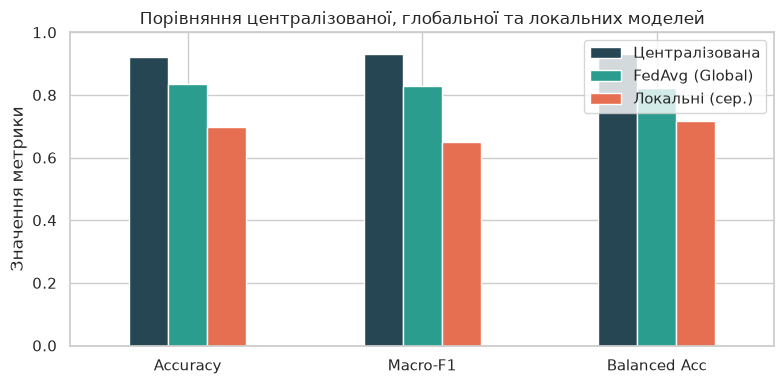

In [29]:
plt.figure(figsize=(8, 5))
metrics_to_plot = ['Accuracy', 'Macro-F1', 'Balanced Acc']
plot_df = pd.DataFrame({
    'Централізована': [central_metrics[m] for m in metrics_to_plot],
    'FedAvg (Global)': [fed_final_metrics[m] for m in metrics_to_plot],
    'Локальні (сер.)': [local_df[m].mean() for m in metrics_to_plot],
}, index=metrics_to_plot)
plot_df.plot(kind='bar', figsize=(8, 4), color=['#264653', '#2a9d8f', '#e76f51'])
plt.title('Порівняння централізованої, глобальної та локальних моделей')
plt.ylabel('Значення метрики'); plt.xticks(rotation=0); plt.ylim(0, 1)
plt.legend(); plt.tight_layout(); plt.show()

**Висновок (порівняння).** Централізована модель — найкраща (має доступ до всіх даних). Глобальна FedAvg-модель близька до неї, але дещо поступається через усереднення. Окремі локальні моделі на Non-IID даних сильно варіюють: для клієнтів з домінантним класом їхня точність на цьому класі може перевищувати глобальну, але в середньому вони гірші. Це підтверджує компроміс між персоналізацією та узагальненням.

### Додатково: зважене vs незважене усереднення

Перевіримо ефект зважування за кількістю прикладів (питання 10–11).

In [30]:
def create_noisy_client_split(X_pool, y_pool, K=5, small_size=300, seed=SEED):
    # K-1 малих клієнтів із ШУМНИМИ (випадковими) мітками + 1 великий "чистий" клієнт
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y_pool))
    n_small = small_size * (K - 1)
    small, big = idx[:n_small], idx[n_small:]
    data = {}
    for k in range(K - 1):
        s = small[k * small_size:(k + 1) * small_size]
        data[k] = (X_pool[s], rng.integers(0, NUM_CLASSES, len(s)))
    data[K - 1] = (X_pool[big], y_pool[big])
    return data

cdata_noisy = create_noisy_client_split(X_pool_s, y_pool, K=5, seed=SEED)
print('Розміри клієнтів:', [len(cdata_noisy[k][1]) for k in range(5)],
      '(<-- малі клієнти мають випадкові мітки)')

m_w, h_w = run_fed_avg(cdata_noisy, X_val_s, Y_val_oh, y_val, rounds=30, local_epochs=20, weighted=True)
m_uw, h_uw = run_fed_avg(cdata_noisy, X_val_s, Y_val_oh, y_val, rounds=30, local_epochs=20, weighted=False)
cmp = pd.DataFrame({
    'Зважене (n_k)': evaluate_model(m_w, X_test_s, y_test),
    'Незважене (1/K)': evaluate_model(m_uw, X_test_s, y_test),
}).T
print(cmp.round(4))

Розміри клієнтів: [300, 300, 300, 300, 8327] (<-- малі клієнти мають випадкові мітки)
                 Accuracy  Macro-F1  Balanced Acc  Log-Loss
Зважене (n_k)      0.9128    0.9253        0.9223    0.3997
Незважене (1/K)    0.8629    0.8678        0.8481    1.1540


**Висновок.** Один великий «чистий» клієнт (~8300 прикладів) і чотири малих клієнти з шумними мітками (по 300). За **незваженого** усереднення шумні клієнти сумарно отримують 80% впливу ($1/5$ кожен) і суттєво псують глобальну модель (високий log-loss). **Зважене** середнє $n_k/\sum n_j$ дає їм лише ~3% кожен, тож чистий клієнт домінує — якість ближча до централізованого навчання. Це і є практичне обґрунтування зважування у FedAvg: внесок клієнта має бути пропорційним обсягу (надійності) його даних.

## Теоретичні питання

1. **Чому для багатокласової класифікації використовують softmax?**  
   Softmax перетворює вектор дійсних логітів $Z$ у вектор ймовірностей із сумою 1, тож вихід можна інтерпретувати як розподіл ймовірностей належності до кожного з класів.

2. **Чому крос-ентропія є природною функцією втрат для логістичної регресії?**  
   Вона випливає з методу максимальної правдоподібності (MLE) для мультиноміального розподілу, суворо штрафує впевнені неправильні передбачення та дає опукле (за фіксованої регуляризації) оптимізаційне поле, на відміну від MSE із softmax.

3. **Чим відрізняється Ridge-регуляризація від Lasso?**  
   Ridge ($L_2$) додає $\frac{\lambda}{2}\|W\|_2^2$ і пропорційно зменшує ваги, не обнуляючи їх. Lasso ($L_1$) додає $\lambda\|W\|_1$, що обнуляє частину ваг і виконує відбір ознак.

4. **Чому зміщення $b$ зазвичай не регуляризують?**  
   $b$ відповідає за зсув/апріорні ймовірності класів і не впливає на «складність» залежності від ознак; його штрафування змістило б модель без користі для контролю перенавчання.

5. **Що таке Data Leakage?**  
   Це потрапляння інформації з валідації/тесту в процес навчання (наприклад, масштабування чи відбір ознак на всіх даних), що дає надто оптимістичні оцінки якості.

6. **Чому тест не можна використовувати для підбору гіперпараметрів?**  
   Підбір на тесті = перенавчання під тест; втрачається об'єктивність фінальної оцінки здатності до узагальнення.

7. **Чому параметри масштабування — лише з тренувальних даних?**  
   Щоб уникнути Data Leakage та імітувати реальне розгортання, де статистики невідомих даних недоступні.

8. **Що таке федеративне навчання і його переваги?**  
   Децентралізоване навчання на локальних пристроях без передачі сирих даних на сервер. Переваги: приватність, менший трафік, відповідність GDPR, можливість навчатися на розподілених джерелах.

9. **Чому сервер не повинен отримувати сирі дані клієнтів?**  
   З міркувань конфіденційності, захисту персональних/комерційних даних і законодавчих вимог.

10. **Чому FedAvg зважує за кількістю прикладів?**  
    Клієнти з більшим обсягом даних мають краще навчені моделі та меншу дисперсію градієнтів, тож їхній внесок має бути пропорційним $n_k/n$.

11. **Що станеться без зважування?**  
    Малі/шумні клієнти отримають надмірний вплив, і глобальна модель погіршиться (див. демонстрацію вище).

12. **Що таке Non-IID дані?**  
    Дані, розподіл яких суттєво відрізняється між клієнтами (пропорції класів, діапазони ознак тощо).

13. **Чому ФЛ погіршується на Non-IID?**  
    Локальні градієнти ведуть до різних локальних оптимумів; усереднення розбіжних ваг дає слабшу глобальну модель.

14. **Що таке client drift?**  
    Надмірне відхилення локальних ваг від глобальної моделі під час кількох локальних епох у напрямку локального оптимуму.

15. **Як кількість локальних епох впливає на глобальну модель?**  
    Більше $E$ зменшує раунди комунікації, але в Non-IID підсилює client drift і може погіршити якість (див. Експеримент 2).

16. **Чи може глобальна модель бути гіршою за централізовану?**  
    Так, майже завжди вона дещо гірша або рівна, бо не бачить об'єднаних даних і втрачає інформацію при усередненні.

17. **Які метрики краще для багатокласової класифікації з дисбалансом?**  
    Macro-F1, balanced accuracy, Cohen's kappa, log-loss та аналіз матриці плутанини (а не тільки accuracy).

In [31]:
print('=' * 60)
print('ПІДСУМКОВІ ЧИСЛА (Global Test)')
print('=' * 60)
print(f'Централізована        | Acc={central_metrics["Accuracy"]:.4f}  MacroF1={central_metrics["Macro-F1"]:.4f}')
print(f'FedAvg alpha=0.3      | Acc={fed_final_metrics["Accuracy"]:.4f}  MacroF1={fed_final_metrics["Macro-F1"]:.4f}')
print(f'Локальні (сер.)       | Acc={local_df["Accuracy"].mean():.4f}  MacroF1={local_df["Macro-F1"].mean():.4f}')
print('-' * 60)
print('Вплив alpha (Macro-F1):', {k: round(v["Macro-F1"], 4) for k, v in exp1_results.items()})
print('Вплив E (Macro-F1):    ', {k: round(v["Macro-F1"], 4) for k, v in exp2_results.items()})
print('Вплив зважування (Macro-F1):', {k: round(v["Macro-F1"], 4) for k, v in cmp.iterrows()})

ПІДСУМКОВІ ЧИСЛА (Global Test)
Централізована        | Acc=0.9197  MacroF1=0.9323
FedAvg alpha=0.3      | Acc=0.8364  MacroF1=0.8286
Локальні (сер.)       | Acc=0.6988  MacroF1=0.6500
------------------------------------------------------------
Вплив alpha (Macro-F1): {'alpha=5.0': 0.9232, 'alpha=1.0': 0.9226, 'alpha=0.3': 0.8286}
Вплив E (Macro-F1):     {'E=1': 0.8906, 'E=5': 0.8286, 'E=10': 0.7831}
Вплив зважування (Macro-F1): {'Зважене (n_k)': np.float64(0.9253), 'Незважене (1/K)': np.float64(0.8678)}


## Загальний висновок

У роботі реалізовано багатокласову логістичну регресію засобами NumPy (softmax, крос-ентропія з Ridge, векторизовані градієнти, міні-батчевий GD) та симуляцію федеративного навчання FedAvg.

**Основні результати:**
1. **Централізована модель** показала найкращу якість і виступає верхньою межею для федеративних підходів.
2. **Неоднорідність (α):** зі зменшенням α (Non-IID) якість глобальної моделі знижується, а збіжність сповільнюється — через client drift.
3. **Кількість локальних епох (E):** за сильного Non-IID завелике E посилює дрейф і може погіршити результат; оптимальним є помірне E.
4. **Зважування FedAvg** за кількістю прикладів важливе за нерівних розмірів клієнтів.
5. **Методологія:** розбиття виконано до масштабування та відбору ознак (без Data Leakage); масштабування навчалося лише на FL Train Pool; підбір гіперпараметрів — лише на Global Validation; фінальна оцінка — на Global Test.